# Calculate the FK heat flux at fixed time

In [2]:
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

from src.utils import make_grid
from src.utils import build_coarse_grid 
from src.utils import read_mitgcm 
import xarray as xr 
import numpy as np 
import gsw 
import importlib 
from src.utils import coarsen_UVWTS 
from MITgcmutils import mds 
importlib.reload(coarsen_UVWTS) # force reload

def buo_coarse(
    ds_grid: xr.Dataset,
    ds_ocean: xr.Dataset,
    boundary_Y: str = "fill"
) -> xr.DataArray:

    # merge the two dataset
    ds = xr.merge([ds_grid, ds_ocean])
    grid = make_grid.make_grid_periodic_x(ds)
    # water collumn
    # Etabar: sea-surface height (j,i) [m]; broadcast add → z_c(k,j,i)
    z_rel = ds["RC"] - ds["Eta"]  # RC is negative, RC - Eta gives the depth of water column
    
    # TEOS10 EOS
    # model output is salinity and potential temperature
    # gsw function need absolute salinity and conservative temperature
    lat0, lon0 = -55.0, 153.0
    lat2d = xr.full_like(ds["T"].isel(k=0), lat0)               # (j,i)
    lon2d = xr.full_like(ds["T"].isel(k=0), np.mod(lon0, 360.)) # (j,i)

    # TEOS-10 sea pressure from depth (returns dbar)
    p_dbar = xr.apply_ufunc(
        gsw.p_from_z, z_rel, lat2d,
        dask="parallelized",
        output_dtypes=[ds["T"].dtype],
    )


    # --- convert SP, θ -> SA, CT -> ρ ---
    SA  = xr.apply_ufunc(gsw.SA_from_SP, ds["S"], p_dbar, lon2d, lat2d,
                         dask='parallelized', output_dtypes=[ds["S"].dtype])
    CT  = xr.apply_ufunc(gsw.CT_from_pt, SA, ds["T"],
                         dask='parallelized', output_dtypes=[ds["T"].dtype])
    rho = xr.apply_ufunc(gsw.rho, SA, CT, p_dbar,
                         dask='parallelized', output_dtypes=[ds["T"].dtype])  # kg m^-3
    # constants
    g = 9.81 # gravity
    rho0 = 1035 # density
    # buoyancy
    b = (-g * (rho - rho0) / rho0).where(ds["hFacC"] > 0)  # m s^-2
    b.name = "buoyancy"
    b.attrs.update(units="m s^-2", long_name="buoyancy (TEOS-10)")
    
    # ---- buoyancy gradient ----
    # Face wet masks (avoid bleeding across land/blocked faces)
    wetU = ds["hFacW"] > 0
    wetV = ds["hFacS"] > 0
    dbdx_u = (grid.diff(b, "X") / ds["DXC"]).where(wetU)                   # (k,j,i_g)
    dbdy_v = (grid.diff(b, "Y", boundary=boundary_Y) / ds["DYC"]).where(wetV)  # (k,j_g,i)
    return b, dbdx_u, dbdy_v

In [3]:
def _k_name(da): # Find the vertical dim name that matches your data 
    for cand in ("k", "Z", "z", "lev", "k_c"): 
        if cand in da.dims: 
            return cand 
            # fallback: assume first dim is vertical (adjust if needed) 
    return da.dims[0]

def mld_integrals_for_MEI( dbdx_u: xr.DataArray, # (k,j,i_g) ∂b/∂x at U 
                           dbdy_v: xr.DataArray, # (k,j_g,i) ∂b/∂y at V 
                           kpphbl_C: xr.DataArray, # (j,i) ML depth at C 
                           ds_grid: xr.Dataset, 
                           grid, 
                           sigma_is_buoyancy: bool = True, 
                           g: float = 9.81, 
                           rho0: float = 1035.0, 
                         ): 
    # ---- 0) Standardize the vertical index 'k' everywhere ---- 
    RF = ds_grid["RF"] # (k_p1), negative downward , 50
    K = RF.sizes["k_p1"] - 1  # 49
    k_index = xr.DataArray(np.arange(K), dims=("k",), name="k") 
    ku = _k_name(dbdx_u) 
    kv = _k_name(dbdy_v) 
    dbdx_u = (dbdx_u.rename({ku: "k"}) .assign_coords(k=k_index) .reset_coords(drop=True)) 
    dbdy_v = (dbdy_v.rename({kv: "k"}) .assign_coords(k=k_index) .reset_coords(drop=True)) 
    # Mixed-layer depth at faces 
    H_C = kpphbl_C.clip(min=0.0) 
    H_U = grid.interp(H_C, "X", to="left") # (j,i_g) 
    H_V = grid.interp(H_C, "Y", to="left") # (j_g,i) 
    # ---- 1) Interfaces as positive-down depths with SAME 'k' coords ---- 
    ztop1d = (-RF.isel(k_p1=slice(0, -1))).rename(k_p1="k").assign_coords(k=k_index) # 0 to Nr -1
    zbot1d = (-RF.isel(k_p1=slice(1, None))).rename(k_p1="k").assign_coords(k=k_index) # 1 to Nr
    # Broadcast to faces (will use positional matching now that 'k' is unified) 
    ztop_U = ztop1d.broadcast_like(dbdx_u) # (k,j,i_g) 
    zbot_U = zbot1d.broadcast_like(dbdx_u) 
    ztop_V = ztop1d.broadcast_like(dbdy_v) # (k,j_g,i) 
    zbot_V = zbot1d.broadcast_like(dbdy_v) 
    # Partial-cell thickness on faces 
    thkU = (zbot_U - ztop_U) * ds_grid["hFacW"] 
    thkV = (zbot_V - ztop_V) * ds_grid["hFacS"] 
    # ---- 2) Overlap thickness with [0, H_face] (no xr.minimum) ---- 
    H3U = H_U.broadcast_like(dbdx_u) 
    H3V = H_V.broadcast_like(dbdy_v) 
    # min(H, zbot) = where(H <= zbot, H, zbot) 
    minHU = xr.where(H3U <= zbot_U, H3U, zbot_U) 
    minHV = xr.where(H3V <= zbot_V, H3V, zbot_V) 
    wU = xr.where(H3U > ztop_U, minHU - ztop_U, 0.0) 
    wV = xr.where(H3V > ztop_V, minHV - ztop_V, 0.0) 
    # clip and enforce partial thickness 
    wU = xr.where(wU > 0, xr.where(wU < thkU, wU, thkU), 0.0) 
    wV = xr.where(wV > 0, xr.where(wV < thkV, wV, thkV), 0.0) 
    # ---- 3) Integrals over 0..H (∑ sigma * dzLoc) ---- 
    intX = (dbdx_u.fillna(0.0) * wU).sum("k") # (j,i_g) 
    intY = (dbdy_v.fillna(0.0) * wV).sum("k") # (j_g,i) 
    # ---- 4) Convert if sigma are density-gradients (yours are buoyancy-gradients) ---- 
    if sigma_is_buoyancy: 
        dBuoyX_Hu, dBuoyY_Hv = intX, intY 
        out_units = "s^-2 m" 
    else: 
        fac = -g / rho0 
        dBuoyX_Hu, dBuoyY_Hv = fac * intX, fac * intY 
        out_units = "kg m^-4 s^-2" 
    # Optional: mask dry faces 
    wetU = (ds_grid["hFacW"] > 0).any("k") 
    wetV = (ds_grid["hFacS"] > 0).any("k") 
    dBuoyX_Hu = dBuoyX_Hu.where(wetU) 
    dBuoyY_Hv = dBuoyY_Hv.where(wetV) 
    dBuoyX_Hu.name, dBuoyY_Hv.name = "dBuoyX_Hu", "dBuoyY_Hv" 
    for da in (dBuoyX_Hu, dBuoyY_Hv): 
        da.attrs["long_name"] = "ML integral of horizontal buoyancy gradient" 
        da.attrs["units"] = out_units 
    return dBuoyX_Hu, dBuoyY_Hv

In [4]:
import numpy as np 
import xarray as xr 
def compute_Lf_MEI( dBuoyX_Hu: xr.DataArray, # (j, i_g) 
                    dBuoyY_Hv: xr.DataArray, # (j_g, i) 
                    b: xr.DataArray, # (k, j, i) buoyancy at C 
                    H_C: xr.DataArray, # (j, i) ML depth at C 
                    f_eff_C: xr.DataArray, # (j, i) 
                    ds_grid: xr.Dataset, 
                    grid, 
                    g: float = 9.81, 
                    rho0: float = 1035.0, 
                    LfMin: float = 1000.0, ): 
    # --- A) Standardize vertical coord 'k' everywhere ----------------------- 
    RF = ds_grid["RF"] # (k_p1) 
    K = RF.sizes["k_p1"] - 1 
    k_idx = xr.DataArray(np.arange(K), dims=("k",), name="k") 
    def to_k(da): 
        # rename vertical dim to 'k' if needed, then assign common index 
        for cand in ("k", "Z", "z", "lev", "k_c"): 
            if cand in da.dims: 
                if cand != "k": 
                    da = da.rename({cand: "k"}) 
                break 
        if "k" in da.dims: 
                da = da.assign_coords(k=k_idx).reset_coords(drop=True) 
        return da 
    b = to_k(b) 
    hFacC = to_k(ds_grid["hFacC"]) # (k,j,i) with unified k 
    # (dBuoyX_Hu, dBuoyY_Hv, H_C, f_eff_C are 2D—no k to fix) 
    # interfaces as positive-down depths with SAME 'k' coords 
    ztop1d = (-RF.isel(k_p1=slice(0, -1))).rename(k_p1="k").assign_coords(k=k_idx) 
    zbot1d = (-RF.isel(k_p1=slice(1, None))).rename(k_p1="k").assign_coords(k=k_idx) 
    ztop = ztop1d.broadcast_like(b) 
    zbot = zbot1d.broadcast_like(b) 
    # --- 1) MsqH at centers from face integrals averaged to C --------------- 
    dBx_C = grid.interp(dBuoyX_Hu, 'X') # U->C 
    dBy_C = grid.interp(dBuoyY_Hv, 'Y') # V->C 
    MsqH = np.sqrt(0.25*(dBx_C**2 + dBy_C**2)) # s^-2 m 
    # --- 2) NHmixLay at C via ML overlap (honor partial cells) -------------- 
    thkC = (zbot - ztop) * hFacC # partial thickness 
    H3C = H_C.assign_coords().broadcast_like(b) # (k,j,i) with unified k 
    # min(H,zbot) without xr.minimum (avoids version issues) 
    minHC = xr.where(H3C <= zbot, H3C, zbot) 
    wC = xr.where(H3C > ztop, minHC - ztop, 0.0) 
    wC = xr.where(wC > 0, xr.where(wC < thkC, wC, thkC), 0.0) 
    # ∂b/∂z at C using interface spacing (downward-positive dz) 
    db = b - b.shift(k=1) 
    dz = (ztop - ztop.shift(k=1)) 
    sigmaR = (db / dz).where(dz.notnull()) 
    sigmaR_pos = xr.where(sigmaR < 0.0, -sigmaR, 0.0) 
    NH_term = (sigmaR_pos * wC).sum("k") # units: s^-2 * m 
    NHmixLay = np.sqrt(NH_term * H_C.clip(min=0.0)).fillna(0.0) 
    # --- 3) Lf at centers --------------------------------------------------- 
    fC = xr.where(f_eff_C > 0, f_eff_C, np.nan) 
    cand1 = MsqH / (fC**2) # m 
    cand2 = NHmixLay / fC # m 
    Lf_center = xr.ufuncs.maximum( xr.ufuncs.maximum(cand1.fillna(0.0), cand2.fillna(0.0)), LfMin ).rename("Lf") 
    Lf_center.attrs.update(long_name="MEI length scale at centers", units="m") 
    # --- 4) centers -> faces for streamfunction denominators ---------------- 
    Lf_U = grid.interp(Lf_center, 'X', to='left') # C->U 
    Lf_V = grid.interp(Lf_center, 'Y', to='left') # C->V 
    Lf_U.name, Lf_V.name = "Lf_U", "Lf_V" 
    return Lf_center, Lf_U, Lf_V

In [5]:
# modules 
from src.utils import read_mitgcm 
from src.utils import coarsen_UVWTS 
from src.utils import build_coarse_grid 
from src.utils import make_grid
import numpy as np 
import xarray as xr 
from MITgcmutils import mds 
from src.utils import mld_avg

box_i = box_j = 10 
# ---------------------------- MITgcm Path ------------------------------------- 
path_scratch = '/scratch/jczhang/' 
path_MITgcm = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm 
# ---------------------------- grid ------------------------------------- 
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir) 
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=box_j, box_i=box_i) 
grid = make_grid.make_grid_periodic_x(ds_coarse) 
# ---------------------------- Ce, ds ------------------------------------- 
# efficiency coefficient Ce 
C_e = 2.49
# hard upper cap - useless for my case, since dx < 111 km 
submeso_Lmax = 2751 # m 
# delta_s: local coarse model gridscale dimension 
delta_sx = ds_coarse["DXC"].clip(max=submeso_Lmax) # (j, i_g) 
delta_sy = ds_coarse["DYC"].clip(max=submeso_Lmax) # (j_g, i) 
# 
index = 20105136
# ---------------------------- mixed layer depth ------------------------------------ 
# mixed layer depth 
kpphbl = xr.open_dataset("../../../../data_5km/save_coarse/13901616_nc/kpphbl_12hmean_coarse.nc", engine="h5netcdf")
kpphbl = kpphbl["kpphbl"].sel(time=index)
H_U = grid.interp(kpphbl, 'X', to='left') # (j, i_g) 
H_V = grid.interp(kpphbl, 'Y', to='left') # (j_g, i) 
# ---------------------------- buoyancy ---------------------------------------------
T = xr.open_dataset("../../../../data_5km/save_coarse/13901616_nc/T_12hmean_coarse.nc", engine="h5netcdf")
T = T["T"].sel(time=index)
S = xr.open_dataset("../../../../data_5km/save_coarse/13901616_nc/S_12hmean_coarse.nc", engine="h5netcdf")
S = S["S"].sel(time=index)
Eta = xr.open_dataset("../../../../data_5km/save_coarse/13901616_nc/Eta_12hmean_coarse.nc", engine="h5netcdf")
Eta = Eta["Eta"].sel(time=index)
#  combine all the variables
ds_ocean_c = xr.Dataset(dict(T=T, S=S, Eta=Eta)) 
# calculate the buoyancy 
b, dBdx_u, dBdy_V = buo_coarse(ds_coarse, ds_ocean_c, "fill") 
# integral over mixed layer 
dBuoyX_Hu, dBuoyY_Hv = mld_integrals_for_MEI( dBdx_u, dBdy_V, kpphbl, ds_coarse, grid, sigma_is_buoyancy=True ) 
# ---------------------------- coriolis and tau------------------------------------- 
f0 = -1.363e-4 # s^-1 
beta = 1.313e-11 # s^-1 m^-1 
subMeso_invTau = 1.4645055034892937e-06 
YC_da = xr.DataArray(ds_coarse["YC"], dims=('j','i')) 
y_ref = float(YC_da.mean()) 
f = (f0 + beta*(YC_da - y_ref)) # (j,i), s^-1 
f_eff = np.hypot(f, subMeso_invTau) 
f_U = grid.interp(f_eff, 'X', to='left') # (j,i_g) 
f_V = grid.interp(f_eff, 'Y', to='left') # (j_g,i) 
# ---------------------------- Lf = max(M/f, NH/|f|, Lf_min)------------------------------------- 
Lf_center, Lf_U, Lf_V = compute_Lf_MEI(dBuoyX_Hu=dBuoyX_Hu, dBuoyY_Hv=dBuoyY_Hv, b=b, H_C=kpphbl.clip(min=0.0), f_eff_C=f_eff, ds_grid=ds_coarse, grid=grid, LfMin=2438.0 ) 
# ---------------------------- mu(z)------------------------------------- 
# RF is negative downward (k_p1 interfaces); use it directly. 
rF = ds_coarse["RF"].rename(k_p1="k") # (k) ≤ 0 
rF_U = rF.broadcast_like(dBdx_u) # (k,j,i_g) 
rF_V = rF.broadcast_like(dBdy_V) # (k,j_g,i) 
# Mixed-layer depths on faces (positive) 
H_U = grid.interp(kpphbl.clip(min=0.0), 'X', to='left') 
H_V = grid.interp(kpphbl.clip(min=0.0), 'Y', to='left') 
# z2H must be negative inside the ML: [-2, 0] 
z2H_U = xr.where(H_U > 0, 2.0 * rF_U / H_U.broadcast_like(dBdx_u), 0.0) 
z2H_V = xr.where(H_V > 0, 2.0 * rF_V / H_V.broadcast_like(dBdy_V), 0.0) 
def mu_from(z2H): 
    q = (1.0 + z2H)**2 
    mu = (1.0 - q) * (1.0 + (5.0/21.0)*q) 
    return xr.where(mu > 0.0, mu, 0.0) 
muU = mu_from(z2H_U) # (k,j,i_g) 
muV = mu_from(z2H_V) # (k,j_g,i) 
# --- gridscale caps at faces (MIN(dx, Lmax), MIN(dy, Lmax)) --- 
dx_cap_U = ds_coarse["DXC"].clip(max=submeso_Lmax) # already (j, i_g) 
dy_cap_V = ds_coarse["DYC"].clip(max=submeso_Lmax) # already (j_g, i) 
# --- 2D streamfunction amplitudes at faces (depth-integrated) --- 
# bring the "other" horizontal component to the target face
dBuoyY_on_U = grid.interp(dBuoyY_Hv, 'Y')          # j_g,i -> j,i
dBuoyY_on_U = grid.interp(dBuoyY_on_U, 'X', to='left')

dBuoyX_on_V = grid.interp(dBuoyX_Hu, 'X')          # j,i_g -> j,i
dBuoyX_on_V = grid.interp(dBuoyX_on_V, 'Y', to='left')

PsiU0 = ( C_e * dBuoyY_on_U * H_U * dx_cap_U / (Lf_U * f_U) ).fillna(0.0)
PsiV0 = (-C_e * dBuoyX_on_V * H_V * dy_cap_V / (Lf_V * f_V) ).fillna(0.0)
# --- 3D streamfunctions using mu(z/H) --- 
muU_ = muU.transpose('k','j','i_g') # ensure consistent order for broadcasting 
muV_ = muV.transpose('k','j_g','i') 
PsiX = PsiU0.broadcast_like(muU_) * muU_ # (k,j,i_g) 
PsiY = PsiV0.broadcast_like(muV_) * muV_ # (k,j_g,i) 
PsiX.name, PsiY.name = "GM_PsiX_MEI", "GM_PsiY_MEI"

# --- grads of mean T on C, then to W (k,j,i) ---
wetU = ds_coarse["hFacW"] > 0
wetV = ds_coarse["hFacS"] > 0

dTdx_U = (grid.diff(T, 'X') / ds_coarse["DXC"]).where(wetU)      # (k,j,i_g)
dTdy_V = (grid.diff(T, 'Y', boundary='fill') / ds_coarse["DYC"]).where(wetV)  # (k,j_g,i)

# bring face-grads to centers
dTdx_C = grid.interp(dTdx_U.fillna(0.0), 'X')    # (k,j,i)
dTdy_C = grid.interp(dTdy_V.fillna(0.0), 'Y')    # (k,j,i)
# average C→W so vertical index matches Ψ(k,·,·) at W levels
dTdx_W = 0.5*(dTdx_C + dTdx_C.shift(k=1))
dTdy_W = 0.5*(dTdy_C + dTdy_C.shift(k=1))

# --- bring Ψ components to centers (same W levels) ---
PsiX_C = grid.interp(PsiX, 'X')    # (k,j,i)
PsiY_C = grid.interp(PsiY, 'Y')    # (k,j,i)

# --- vertical eddy temp flux from cross product ----------------------------
Fz_T_cross = (PsiX_C * dTdy_W - PsiY_C * dTdx_W).rename("Fz_T_cross")   # (k,j,i)
Fz_T_cross.attrs.update(long_name="(Ψ × ∇T)_z", units="K m s^-1?  see note")

# (optional) convert to heat units
rho0, cp = 1035.0, 3990.0
Qz_T_cross = (rho0 * cp) * Fz_T_cross

Qz_T_cross.name = "Qz_T_cross"
Qz_T_cross.attrs.update(units="W m^-2")
submeso_wT_FK = mld_avg.mld_avg(Qz_T_cross, kpphbl, ds_coarse)

# Load True and prediction

In [6]:
# compare the npz data with data after data_loader
import torch
# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid

from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf
import importlib
from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
XC_c = ds_coarse["XC"]
YC_c = ds_coarse["YC"]

y_true_path = "../../../outputs/cfg_19/test_y_true.npy"
y_pred_path = "../../../outputs/cfg_19/test_y_pred.npy"
y_true = np.load(y_true_path)   # shape (N,1,H,W)
y_pred = np.load(y_pred_path)   # shape (N,1,H,W)

# Plot

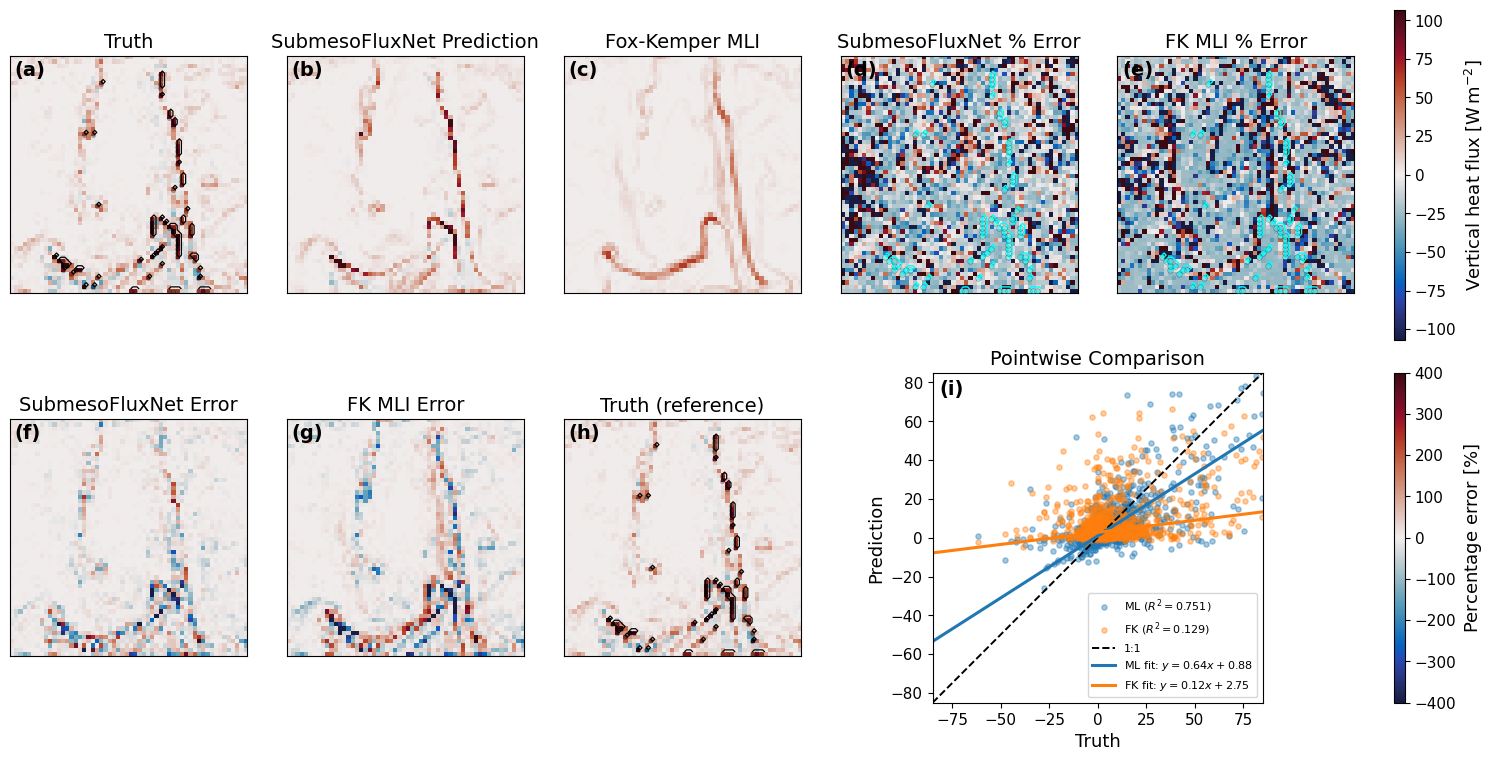

Pixels with |truth| > 50.0: 76


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import matplotlib.gridspec as gridspec
import cmocean.cm as cmo

# =============================
# helpers
# =============================
def sym_limit(*arrays, q=0.995):
    vals = []
    for a in arrays:
        a = np.asarray(a)
        vals.append(np.abs(a[np.isfinite(a)]).ravel())
    vals = np.concatenate(vals)
    return float(np.nanquantile(vals, q))

def calc_r2(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    m = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[m]
    y_pred = y_pred[m]
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

def fit_line(x, y):
    x = np.asarray(x).ravel()
    y = np.asarray(y).ravel()
    m = np.isfinite(x) & np.isfinite(y)
    x = x[m]
    y = y[m]
    a, b = np.polyfit(x, y, 1)
    return a, b

def calc_pct_error(pred, true, eps=1e-12):
    """
    Real percentage error:
        100 * (pred - true) / true

    No clipping / no cap.
    Only mask where |true| <= eps.
    """
    pred = np.asarray(pred, dtype=float)
    true = np.asarray(true, dtype=float)

    pct = np.full_like(true, np.nan, dtype=float)
    m = np.isfinite(pred) & np.isfinite(true) & (np.abs(true) > eps)
    pct[m] = 100.0 * (pred[m] - true[m]) / true[m]
    return pct

def mark_selected_pixels(
    ax,
    mask,
    contour_color="black",
    point_color="black",
    edge_color=None,
    linewidth=1.0,
    size=18,
    contour_alpha=0.35,
    point_alpha=0.30,
):
    """Draw transparent contour and pixel-center markers for a boolean mask."""
    if not np.any(mask):
        return

    yy, xx = np.where(mask)

    cs = ax.contour(
        mask.astype(float),
        levels=[0.5],
        colors=contour_color,
        linewidths=linewidth,
        origin="lower",
    )

    # make contour transparent
    try:
        for coll in cs.collections:
            coll.set_alpha(contour_alpha)
    except AttributeError:
        pass

    ax.scatter(
        xx, yy,
        s=size,
        c=point_color,
        edgecolors=edge_color,
        linewidths=0.35 if edge_color is not None else 0.0,
        alpha=point_alpha,
        zorder=4,
    )

# =============================
# data
# =============================
true = np.asarray(y_true[298, 0, :, :])
pred = np.asarray(y_pred[298, 0, :, :])
fk   = np.asarray(submeso_wT_FK[62:118, 2:58])

err_pred = pred - true
err_fk   = fk - true

pct_err_pred = calc_pct_error(pred, true, eps=1e-12)
pct_err_fk   = calc_pct_error(fk, true, eps=1e-12)

# mark pixels where |truth| > 50
truth_threshold = 50.0
truth_mask = np.abs(true) > truth_threshold

# =============================
# limits
# =============================
field_lim = sym_limit(true, q=0.995)
err_lim   = sym_limit(err_pred, err_fk, q=0.995)

field_norm = TwoSlopeNorm(vcenter=0.0, vmin=-field_lim, vmax=field_lim)
err_norm   = TwoSlopeNorm(vcenter=0.0, vmin=-err_lim, vmax=err_lim)
pct_norm   = TwoSlopeNorm(vcenter=0.0, vmin=-400, vmax=400)

# =============================
# scatter stats
# =============================
x_true = true.ravel()
y_pred_flat = pred.ravel()
y_fk_flat = fk.ravel()

m_pred = np.isfinite(x_true) & np.isfinite(y_pred_flat)
m_fk   = np.isfinite(x_true) & np.isfinite(y_fk_flat)

r2_pred = calc_r2(x_true, y_pred_flat)
r2_fk   = calc_r2(x_true, y_fk_flat)

a_pred, b_pred = fit_line(x_true[m_pred], y_pred_flat[m_pred])
a_fk, b_fk     = fit_line(x_true[m_fk], y_fk_flat[m_fk])

xy_lim = sym_limit(x_true, y_pred_flat, y_fk_flat, q=0.995)

# =============================
# figure layout
# =============================
fig = plt.figure(figsize=(18, 9))
gs = gridspec.GridSpec(
    2, 6,
    width_ratios=[1, 1, 1, 1, 1, 0.045],
    height_ratios=[1, 1],
    wspace=0.20,
    hspace=0.10
)

ax00 = fig.add_subplot(gs[0, 0])
ax01 = fig.add_subplot(gs[0, 1])
ax02 = fig.add_subplot(gs[0, 2])
ax03 = fig.add_subplot(gs[0, 3])
ax04 = fig.add_subplot(gs[0, 4])
cax0 = fig.add_subplot(gs[0, 5])

ax10 = fig.add_subplot(gs[1, 0])
ax11 = fig.add_subplot(gs[1, 1])
ax12 = fig.add_subplot(gs[1, 2])
ax13 = fig.add_subplot(gs[1, 3:5])
cax1 = fig.add_subplot(gs[1, 5])

title_fs = 14
label_fs = 13
tick_fs = 11
panel_fs = 14

# =============================
# top row
# =============================
im0 = ax00.imshow(true, origin="lower", cmap=cmo.balance, norm=field_norm, aspect="equal")
im1 = ax01.imshow(pred, origin="lower", cmap=cmo.balance, norm=field_norm, aspect="equal")
im2 = ax02.imshow(fk,   origin="lower", cmap=cmo.balance, norm=field_norm, aspect="equal")
im3 = ax03.imshow(pct_err_pred, origin="lower", cmap=cmo.balance, norm=pct_norm, aspect="equal")
im4 = ax04.imshow(pct_err_fk,   origin="lower", cmap=cmo.balance, norm=pct_norm, aspect="equal")

ax00.set_title("Truth", fontsize=title_fs)
ax01.set_title("SubmesoFluxNet Prediction", fontsize=title_fs)
ax02.set_title("Fox-Kemper MLI", fontsize=title_fs)
ax03.set_title("SubmesoFluxNet % Error", fontsize=title_fs)
ax04.set_title("FK MLI % Error", fontsize=title_fs)

# mark |truth| > 50 on truth
mark_selected_pixels(
    ax00, truth_mask,
    contour_color="black",
    point_color="black",
    edge_color=None,
    linewidth=0.9,
    size=14,
    contour_alpha=0.35,
    point_alpha=0.30,
)

# mark same points on both % error plots
for ax in [ax03, ax04]:
    mark_selected_pixels(
        ax, truth_mask,
        contour_color="cyan",
        point_color="cyan",
        edge_color="black",
        linewidth=1.0,
        size=16,
        contour_alpha=0.45,
        point_alpha=0.40,
    )

# =============================
# bottom row
# =============================
im5 = ax10.imshow(err_pred, origin="lower", cmap=cmo.balance, norm=err_norm, aspect="equal")
im6 = ax11.imshow(err_fk,   origin="lower", cmap=cmo.balance, norm=err_norm, aspect="equal")
im7 = ax12.imshow(true, origin="lower", cmap=cmo.balance, norm=field_norm, aspect="equal")

ax10.set_title("SubmesoFluxNet Error", fontsize=title_fs)
ax11.set_title("FK MLI Error", fontsize=title_fs)
ax12.set_title("Truth (reference)", fontsize=title_fs)

# also mark on bottom truth reference
mark_selected_pixels(
    ax12, truth_mask,
    contour_color="black",
    point_color="black",
    edge_color=None,
    linewidth=0.9,
    size=14,
    contour_alpha=0.35,
    point_alpha=0.30,
)

# =============================
# scatter
# =============================
xx = np.linspace(-xy_lim, xy_lim, 200)

ax13.scatter(
    x_true[m_pred], y_pred_flat[m_pred],
    s=14, alpha=0.40, label=fr"ML ($R^2={r2_pred:.3f}$)"
)
ax13.scatter(
    x_true[m_fk], y_fk_flat[m_fk],
    s=14, alpha=0.40, label=fr"FK ($R^2={r2_fk:.3f}$)"
)

ax13.plot(xx, xx, "k--", lw=1.4, label="1:1")
ax13.plot(xx, a_pred * xx + b_pred, lw=2.2,
          label=fr"ML fit: $y={a_pred:.2f}x+{b_pred:.2f}$")
ax13.plot(xx, a_fk * xx + b_fk, lw=2.2,
          label=fr"FK fit: $y={a_fk:.2f}x+{b_fk:.2f}$")

ax13.set_xlim(-xy_lim, xy_lim)
ax13.set_ylim(-xy_lim, xy_lim)
ax13.set_aspect("equal", adjustable="box")
ax13.set_title("Pointwise Comparison", fontsize=title_fs)
ax13.set_xlabel("Truth", fontsize=label_fs)
ax13.set_ylabel("Prediction", fontsize=label_fs)
ax13.tick_params(labelsize=tick_fs)
ax13.legend(fontsize=8, loc="lower right", frameon=True)

# =============================
# panel labels
# =============================
panel_labels = [
    (ax00, "(a)"), (ax01, "(b)"), (ax02, "(c)"),
    (ax03, "(d)"), (ax04, "(e)"),
    (ax10, "(f)"), (ax11, "(g)"), (ax12, "(h)"), (ax13, "(i)")
]

for ax, lab in panel_labels:
    ax.text(
        0.02, 0.98, lab,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=panel_fs,
        fontweight="bold"
    )

# =============================
# clean map axes
# =============================
for ax in [ax00, ax01, ax02, ax03, ax04, ax10, ax11, ax12]:
    ax.set_xticks([])
    ax.set_yticks([])

# =============================
# colorbars
# =============================
cb0 = fig.colorbar(im2, cax=cax0)
cb0.set_label(r"Vertical heat flux [$\mathrm{W\,m^{-2}}$]", fontsize=label_fs)
cb0.ax.tick_params(labelsize=tick_fs)

cb1 = fig.colorbar(im4, cax=cax1)
cb1.set_label(r"Percentage error [$\%$]", fontsize=label_fs)
cb1.ax.tick_params(labelsize=tick_fs)

plt.savefig("fk_vs_ml_comparison_with_pct_error_marked.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Pixels with |truth| > {truth_threshold:.1f}: {np.sum(truth_mask)}")

# Save the FK data

run the modules in the first section before run it

In [14]:
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# ==============================
# modules
# ==============================
import numpy as np
import xarray as xr

from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import make_grid
from src.utils import mld_avg

# You said these are already available in your environment/module
# from your_module import buo_coarse, mld_integrals_for_MEI, compute_Lf_MEI

# ==============================
# helpers for resumable npz
# ==============================
def load_existing_npz(npz_path: str):
    """Load existing npz if present; otherwise return empty arrays."""
    if not os.path.exists(npz_path):
        return np.array([], dtype=np.int64), None

    with np.load(npz_path) as npz:
        t_old = npz["time_index"].astype(np.int64)
        x_old = npz["data"].astype(np.float32)

    return t_old, x_old


def save_npz_sorted(npz_path: str, time_index: np.ndarray, data: np.ndarray):
    """Save sorted by time_index."""
    order = np.argsort(time_index)
    np.savez_compressed(
        npz_path,
        time_index=time_index[order].astype(np.int64),
        data=data[order].astype(np.float32),
    )


def append_and_save(npz_path: str, t_old, x_old, t_new, x_new):
    """Append new results, remove duplicates (new wins), sort, and save."""
    if t_new.size == 0:
        if x_old is not None:
            save_npz_sorted(npz_path, t_old, x_old)
        return

    if x_old is None or t_old.size == 0:
        save_npz_sorted(npz_path, t_new, x_new)
        return

    # concatenate old + new, but let new overwrite duplicates
    t_cat = np.concatenate([t_old, t_new], axis=0)
    x_cat = np.concatenate([x_old, x_new], axis=0)

    # keep last occurrence of each time
    rev_idx = np.arange(len(t_cat) - 1, -1, -1)
    _, unique_pos_rev = np.unique(t_cat[rev_idx], return_index=True)
    keep = rev_idx[unique_pos_rev]
    keep = np.sort(keep)

    t_final = t_cat[keep]
    x_final = x_cat[keep]

    save_npz_sorted(npz_path, t_final, x_final)


# ==============================
# FK computation for one time
# ==============================
def compute_fk_submeso_heat_flux_one_time(
    index: int,
    ds_coarse: xr.Dataset,
    grid,
    kpphbl_da: xr.DataArray,
    T_da: xr.DataArray,
    S_da: xr.DataArray,
    Eta_da: xr.DataArray,
    C_e: float = 2.49,
    submeso_Lmax: float = 2751.0,
    subMeso_invTau: float = 1.4645055034892937e-06 ,
    LfMin: float = 2438.0,
    f0: float = -1.363e-4,
    beta: float = 1.313e-11,
    rho0: float = 1035.0,
    cp: float = 3990.0,
):
    """
    Compute FK submesoscale vertical heat flux averaged over the MLD
    at one time index. Returns a (j, i) numpy array.
    """

    # ----------------------------
    # mixed layer depth
    # ----------------------------
    kpphbl = kpphbl_da.sel(time=index)

    # ----------------------------
    # buoyancy variables
    # ----------------------------
    T = T_da.sel(time=index)
    S = S_da.sel(time=index)
    Eta = Eta_da.sel(time=index)

    ds_ocean_c = xr.Dataset(dict(T=T, S=S, Eta=Eta))

    # calculate buoyancy and horizontal buoyancy gradients
    b, dBdx_u, dBdy_V = buo_coarse(ds_coarse, ds_ocean_c, "fill")

    # mixed-layer integrals
    dBuoyX_Hu, dBuoyY_Hv = mld_integrals_for_MEI(
        dBdx_u,
        dBdy_V,
        kpphbl,
        ds_coarse,
        grid,
        sigma_is_buoyancy=True,
    )

    # ----------------------------
    # coriolis and effective f
    # ----------------------------
    YC_da = xr.DataArray(ds_coarse["YC"], dims=("j", "i"))
    y_ref = float(YC_da.mean())

    f = f0 + beta * (YC_da - y_ref)       # (j,i)
    f_eff = np.hypot(f, subMeso_invTau)   # (j,i)

    f_U = grid.interp(f_eff, "X", to="left")
    f_V = grid.interp(f_eff, "Y", to="left")

    # ----------------------------
    # frontal width scale
    # ----------------------------
    Lf_center, Lf_U, Lf_V = compute_Lf_MEI(
        dBuoyX_Hu=dBuoyX_Hu,
        dBuoyY_Hv=dBuoyY_Hv,
        b=b,
        H_C=kpphbl.clip(min=0.0),
        f_eff_C=f_eff,
        ds_grid=ds_coarse,
        grid=grid,
        LfMin=LfMin,
    )

    # ----------------------------
    # vertical structure mu(z)
    # ----------------------------
    rF = ds_coarse["RF"].rename(k_p1="k")
    rF_U = rF.broadcast_like(dBdx_u)
    rF_V = rF.broadcast_like(dBdy_V)

    H_U = grid.interp(kpphbl.clip(min=0.0), "X", to="left")
    H_V = grid.interp(kpphbl.clip(min=0.0), "Y", to="left")

    z2H_U = xr.where(H_U > 0, 2.0 * rF_U / H_U.broadcast_like(dBdx_u), 0.0)
    z2H_V = xr.where(H_V > 0, 2.0 * rF_V / H_V.broadcast_like(dBdy_V), 0.0)

    def mu_from(z2H):
        q = (1.0 + z2H) ** 2
        mu = (1.0 - q) * (1.0 + (5.0 / 21.0) * q)
        return xr.where(mu > 0.0, mu, 0.0)

    muU = mu_from(z2H_U)
    muV = mu_from(z2H_V)

    # ----------------------------
    # gridscale caps
    # ----------------------------
    dx_cap_U = ds_coarse["DXC"].clip(max=submeso_Lmax)
    dy_cap_V = ds_coarse["DYC"].clip(max=submeso_Lmax)

    # ----------------------------
    # streamfunction amplitudes
    # ----------------------------
    dBuoyY_on_U = grid.interp(dBuoyY_Hv, "Y")
    dBuoyY_on_U = grid.interp(dBuoyY_on_U, "X", to="left")

    dBuoyX_on_V = grid.interp(dBuoyX_Hu, "X")
    dBuoyX_on_V = grid.interp(dBuoyX_on_V, "Y", to="left")

    PsiU0 = (C_e * dBuoyY_on_U * H_U * dx_cap_U / (Lf_U * f_U)).fillna(0.0)
    PsiV0 = (-C_e * dBuoyX_on_V * H_V * dy_cap_V / (Lf_V * f_V)).fillna(0.0)

    muU_ = muU.transpose("k", "j", "i_g")
    muV_ = muV.transpose("k", "j_g", "i")

    PsiX = PsiU0.broadcast_like(muU_) * muU_
    PsiY = PsiV0.broadcast_like(muV_) * muV_

    PsiX.name = "GM_PsiX_MEI"
    PsiY.name = "GM_PsiY_MEI"

    # ----------------------------
    # mean T gradients
    # ----------------------------
    wetU = ds_coarse["hFacW"] > 0
    wetV = ds_coarse["hFacS"] > 0

    dTdx_U = (grid.diff(T, "X") / ds_coarse["DXC"]).where(wetU)
    dTdy_V = (grid.diff(T, "Y", boundary="fill") / ds_coarse["DYC"]).where(wetV)

    dTdx_C = grid.interp(dTdx_U.fillna(0.0), "X")
    dTdy_C = grid.interp(dTdy_V.fillna(0.0), "Y")

    dTdx_W = 0.5 * (dTdx_C + dTdx_C.shift(k=1))
    dTdy_W = 0.5 * (dTdy_C + dTdy_C.shift(k=1))

    # ----------------------------
    # streamfunction at centers
    # ----------------------------
    PsiX_C = grid.interp(PsiX, "X")
    PsiY_C = grid.interp(PsiY, "Y")

    # ----------------------------
    # vertical temperature / heat flux
    # ----------------------------
    Fz_T_cross = (PsiX_C * dTdy_W - PsiY_C * dTdx_W).rename("Fz_T_cross")
    Qz_T_cross = (rho0 * cp) * Fz_T_cross
    Qz_T_cross.name = "Qz_T_cross"
    Qz_T_cross.attrs["units"] = "W m^-2"

    submeso_wT_FK = mld_avg.mld_avg(Qz_T_cross, kpphbl, ds_coarse)

    return np.asarray(submeso_wT_FK, dtype=np.float32)


# ==============================
# main batch driver
# ==============================
def main():
    # ----------------------------
    # parameters
    # ----------------------------
    
    box_i = box_j = 10
    start_time = 19588464
    n_snapshots = 720
    time_step = 1728

    # output
    out_npz = "./FK_submesoflux.npz"

    # MITgcm grid
    path_scratch = "/scratch/jczhang/"
    path_MITgcm = "MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/"
    grid_dir = path_scratch + path_MITgcm

    # coarse nc files
    base_nc = "../../../../data_5km/save_coarse/13901616_nc"
    path_kpphbl = f"{base_nc}/kpphbl_12hmean_coarse.nc"
    path_T = f"{base_nc}/T_12hmean_coarse.nc"
    path_S = f"{base_nc}/S_12hmean_coarse.nc"
    path_Eta = f"{base_nc}/Eta_12hmean_coarse.nc"

    # ----------------------------
    # load grid once
    # ----------------------------
    print("Loading grid...")
    ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
    ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine, box_j=box_j, box_i=box_i)
    grid = make_grid.make_grid_periodic_x(ds_coarse)

    # ----------------------------
    # open datasets once
    # ----------------------------
    print("Opening datasets...")
    ds_kpphbl = xr.open_dataset(path_kpphbl, engine="h5netcdf")
    ds_T = xr.open_dataset(path_T, engine="h5netcdf")
    ds_S = xr.open_dataset(path_S, engine="h5netcdf")
    ds_Eta = xr.open_dataset(path_Eta, engine="h5netcdf")

    kpphbl_da = ds_kpphbl["kpphbl"]
    T_da = ds_T["T"]
    S_da = ds_S["S"]
    Eta_da = ds_Eta["Eta"]

    # ----------------------------
    # determine target time list
    # fixed interval = 1728
    # ----------------------------
    all_times = np.asarray(kpphbl_da["time"].values, dtype=np.int64)
    all_times_set = set(all_times.tolist())
    
    target_times_full = np.asarray(
        [start_time + n * time_step for n in range(n_snapshots)],
        dtype=np.int64
    )
    
    target_times = np.asarray(
        [t for t in target_times_full if int(t) in all_times_set],
        dtype=np.int64
    )
    
    missing_times = [int(t) for t in target_times_full if int(t) not in all_times_set]
    
    if target_times.size == 0:
        raise ValueError("None of the requested target times exist in the dataset.")
    
    print(f"Requested start time: {start_time}")
    print(f"Time interval: {time_step}")
    print(f"Requested number of snapshots: {n_snapshots}")
    print(f"Available snapshots to compute: {len(target_times)}")
    
    if missing_times:
        print(f"Warning: {len(missing_times)} requested times are missing from the dataset.")
        print(f"First few missing times: {missing_times[:10]}")
    
    print(f"Time range to compute: {target_times[0]} ... {target_times[-1]}")
    # ----------------------------
    # load old results if any
    # ----------------------------
    t_old, x_old = load_existing_npz(out_npz)
    saved_set = set(t_old.tolist())

    todo_times = [int(t) for t in target_times if int(t) not in saved_set]

    print(f"Already saved: {len(t_old)}")
    print(f"Need to compute: {len(todo_times)}")

    if len(todo_times) == 0:
        print("Nothing to do. All target snapshots already saved.")
        return

    # infer output shape from first target if no old data
    sample_shape = None
    if x_old is not None:
        sample_shape = x_old.shape[1:]

    new_times = []
    new_data = []

    # ----------------------------
    # main loop
    # ----------------------------
    for n, t in enumerate(todo_times, start=1):
        print(f"[{n}/{len(todo_times)}] Computing time = {t}")

        try:
            fk_flux = compute_fk_submeso_heat_flux_one_time(
                index=t,
                ds_coarse=ds_coarse,
                grid=grid,
                kpphbl_da=kpphbl_da,
                T_da=T_da,
                S_da=S_da,
                Eta_da=Eta_da,
            )

            if sample_shape is None:
                sample_shape = fk_flux.shape
                print(f"Detected output shape: {sample_shape}")

            if fk_flux.shape != sample_shape:
                raise ValueError(
                    f"Output shape mismatch at time {t}: got {fk_flux.shape}, expected {sample_shape}"
                )

            new_times.append(t)
            new_data.append(fk_flux)

            # save every snapshot so the run is fully resumable
            append_and_save(
                out_npz,
                t_old,
                x_old,
                np.asarray([t], dtype=np.int64),
                np.asarray([fk_flux], dtype=np.float32),
            )

            # refresh in-memory old arrays after each successful save
            t_old, x_old = load_existing_npz(out_npz)

        except Exception as e:
            print(f"Failed at time {t}: {e}")
            continue

    print("Done.")
    t_final, x_final = load_existing_npz(out_npz)
    print(f"Final saved snapshots: {len(t_final)}")
    print(f"Saved file: {out_npz}")


if __name__ == "__main__":
    main()

Loading grid...
Opening datasets...
Requested start time: 19588464
Time interval: 1728
Requested number of snapshots: 720
Available snapshots to compute: 720
Time range to compute: 19588464 ... 20830896
Already saved: 0
Need to compute: 720
[1/720] Computing time = 19588464
Detected output shape: (120, 60)
[2/720] Computing time = 19590192
[3/720] Computing time = 19591920
[4/720] Computing time = 19593648
[5/720] Computing time = 19595376
[6/720] Computing time = 19597104
[7/720] Computing time = 19598832
[8/720] Computing time = 19600560
[9/720] Computing time = 19602288
[10/720] Computing time = 19604016
[11/720] Computing time = 19605744
[12/720] Computing time = 19607472
[13/720] Computing time = 19609200
[14/720] Computing time = 19610928
[15/720] Computing time = 19612656
[16/720] Computing time = 19614384
[17/720] Computing time = 19616112
[18/720] Computing time = 19617840
[19/720] Computing time = 19619568
[20/720] Computing time = 19621296
[21/720] Computing time = 19623024


# Calculate the averaged FK heat R2

In [15]:
# load the True 
# total number = 9014
# train = 7211, val = 901, test = 902
# best test = 298 + 7211 + 901
# test start time = 19588464, dt = 1728
start_time = 19588464
snapshots = 720
time_step = 1728
time_index_list = start_time + time_step * np.arange(snapshots, dtype=np.int64)

data = np.load("../../../data/mld/wT.npz")
wT_time_index = data["time_index"]
wT_sub = data["data"]
data = np.load("./FK_submesoflux.npz")
FK_time_index = data["time_index"] 
wT_FK = data["data"][:,62:118, 2:58]
# get the FK heat flux 
# check which requested times exist
mask_wT = np.isin(wT_time_index, time_index_list)
time_sel = wT_time_index[mask_wT]
wT_sel = wT_sub[mask_wT]
# FK submesoscale heat flux
mask_FK = np.isin(FK_time_index, time_index_list)
time_sel_FK = FK_time_index[mask_FK]
wT_sel_FK = wT_FK[mask_FK]
print(wT_sel.shape)
print(wT_sel_FK.shape)

(720, 56, 56)
(720, 56, 56)


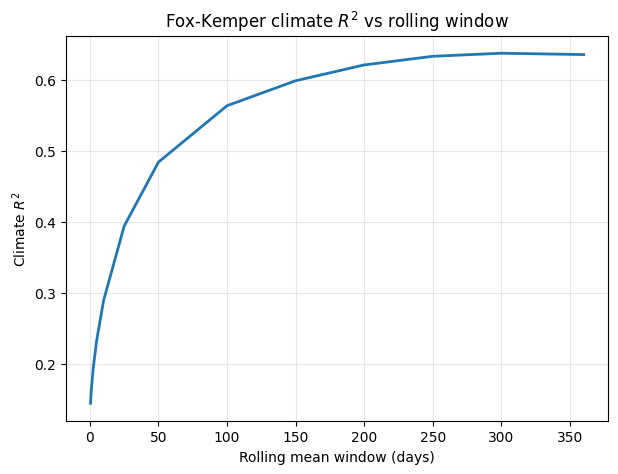

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def rolling_mean_time(x, window):
    """
    Rolling mean along time axis (axis=0).
    Keeps same shape; first window-1 entries are NaN.
    """
    x = np.asarray(x, dtype=np.float64)
    T = x.shape[0]
    flat = x.reshape(T, -1)  # (time, pixels)
    rolled = pd.DataFrame(flat).rolling(window=window, min_periods=window).mean().values
    return rolled.reshape(x.shape)

def r2_all(y_true, y_pred):
    """
    Global R^2 over all valid space-time points.
    """
    yt = np.asarray(y_true, dtype=np.float64).ravel()
    yp = np.asarray(y_pred, dtype=np.float64).ravel()

    m = np.isfinite(yt) & np.isfinite(yp)
    yt = yt[m]
    yp = yp[m]

    if yt.size == 0:
        return np.nan

    ss_res = np.sum((yt - yp) ** 2)
    ss_tot = np.sum((yt - np.mean(yt)) ** 2)

    if ss_tot == 0:
        return np.nan

    return 1.0 - ss_res / ss_tot

def climate_r2_rolling(y_true, y_pred, window):
    yt_roll = rolling_mean_time(y_true, window)
    yp_roll = rolling_mean_time(y_pred, window)
    return r2_all(yt_roll, yp_roll)

# -----------------------------------
# truth = wT_sel
# FK    = wT_sel_FK
# -----------------------------------
windows = np.array([1, 2, 5, 10, 20, 50, 100, 200, 300, 400, 500, 600, 720])
r2_vals = []

for w in windows:
    r2_vals.append(climate_r2_rolling(wT_sel, wT_sel_FK, w))

r2_vals = np.asarray(r2_vals)

# -----------------------------------
# plot
# -----------------------------------
plt.figure(figsize=(7, 5))
plt.plot(windows / 2, r2_vals, linewidth=2)
plt.xlabel("Rolling mean window (days)")
plt.ylabel(r"Climate $R^2$")
plt.title("Fox-Kemper climate $R^2$ vs rolling window")
plt.grid(True, alpha=0.3)
plt.show()

# Compare the model and FK

In [17]:
# load the True 
# total number = 9014
# train = 7211, val = 901, test = 902
# best test = 298 + 7211 + 901
# test start time = 19588464, dt = 1728
start_time = 19588464
snapshots = 720
time_step = 1728
time_index_list = start_time + time_step * np.arange(snapshots, dtype=np.int64)

data = np.load("../../../data/mld/wT.npz")
wT_time_index = data["time_index"]
wT_sub = data["data"]
data = np.load("./FK_submesoflux.npz")
FK_time_index = data["time_index"] 
wT_FK = data["data"][:,62:118, 2:58]
# get the FK heat flux 
# check which requested times exist
mask_wT = np.isin(wT_time_index, time_index_list)
time_sel = wT_time_index[mask_wT]
wT_sel = wT_sub[mask_wT]
# FK submesoscale heat flux
mask_FK = np.isin(FK_time_index, time_index_list)
time_sel_FK = FK_time_index[mask_FK]
wT_sel_FK = wT_FK[mask_FK]
print(wT_sel.shape)
print(wT_sel_FK.shape)

(720, 56, 56)
(720, 56, 56)


In [18]:
# compare the npz data with data after data_loader
import torch
# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid

from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf
import importlib
from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
XC_c = ds_coarse["XC"]
YC_c = ds_coarse["YC"]

y_true_path = "../../../outputs/cfg_19/test_y_true.npy"
y_pred_path = "../../../outputs/cfg_19/test_y_pred.npy"
y_true = np.load(y_true_path)   # shape (N,1,H,W)
y_pred = np.load(y_pred_path)   # shape (N,1,H,W)
print(y_true.shape)
print(y_pred.shape)

(902, 1, 56, 56)
(902, 1, 56, 56)


In [19]:
import numpy as np
import matplotlib.pyplot as plt

def plot_r2_window_comparison_from_data(
    y_true_a, y_pred_a,
    y_true_b, y_pred_b,
    *,
    windows=(1, 2, 5, 10, 20, 50, 100, 200, 300, 400, 500, 600, 720),
    stride: int = 1,
    label_a: str = "Fox-Kemper",
    label_b: str = "ML Model",
    title: str = r"Time-mean $R^2$ versus time window",
    savepath: str | None = None,
    dpi: int = 300,
):
    """
    Compute and plot two rolling-window climate R^2 curves on one panel.

    Inputs can be:
      (N,H,W) or (N,1,H,W)
    """

    def squeeze_to_3d(y):
        y = np.asarray(y, dtype=np.float64)
        if y.ndim == 4:
            y = y[:, 0]
        if y.ndim != 3:
            raise ValueError(f"Expect (N,H,W) or (N,1,H,W), got {y.shape}")
        return y

    def r2_map(a, b, eps=1e-12):
        aa = np.asarray(a, dtype=np.float64).ravel()
        bb = np.asarray(b, dtype=np.float64).ravel()
        m = np.isfinite(aa) & np.isfinite(bb)
        aa = aa[m]
        bb = bb[m]
        if aa.size < 2:
            return np.nan
        sse = np.sum((bb - aa) ** 2)
        sst = np.sum((aa - aa.mean()) ** 2)
        return 1.0 - sse / (sst + eps)

    def compute_curve(y_true, y_pred, windows, stride):
        Yt = squeeze_to_3d(y_true)
        Yp = squeeze_to_3d(y_pred)

        if Yt.shape != Yp.shape:
            raise ValueError(f"Shape mismatch: {Yt.shape} vs {Yp.shape}")

        N = Yt.shape[0]
        r2_vals = []
        used_windows = []

        for W in windows:
            W = int(W)
            if W < 1 or W > N:
                r2_vals.append(np.nan)
                used_windows.append(W)
                continue

            starts = np.arange(0, N - W + 1, stride, dtype=int)
            r2_list = []

            for s in starts:
                yt_bar = np.nanmean(Yt[s:s+W], axis=0)
                yp_bar = np.nanmean(Yp[s:s+W], axis=0)
                r2_list.append(r2_map(yt_bar, yp_bar))

            r2_vals.append(np.nanmean(r2_list))
            used_windows.append(W)

        return np.asarray(used_windows), np.asarray(r2_vals)

    # compute the two curves
    windows_a, r2_a = compute_curve(y_true_a, y_pred_a, windows, stride)
    windows_b, r2_b = compute_curve(y_true_b, y_pred_b, windows, stride)

    # plot
    fig, ax = plt.subplots(figsize=(7.2, 5.0), dpi=dpi)

    ax.plot(
        windows_a/2, r2_a,
        marker="o", linewidth=2, markersize=6,
        label=label_a
    )
    ax.plot(
        windows_b/2, r2_b,
        marker="o", linewidth=2, markersize=6,
        label=label_b
    )

    ax.set_xlabel("Rolling mean time window (days)", fontsize=12)
    ax.set_ylabel(r"Time-mean $R^2$", fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.set_ylim(0, 1.0)
    ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=11)
    ax.legend(frameon=False, fontsize=11)


    plt.tight_layout()

    if savepath is not None:
        plt.savefig(savepath, dpi=dpi, bbox_inches="tight")
        print("Saved:", savepath)

    plt.show()

    return (windows_a, r2_a), (windows_b, r2_b)

Saved: climate_r2_comparison.png


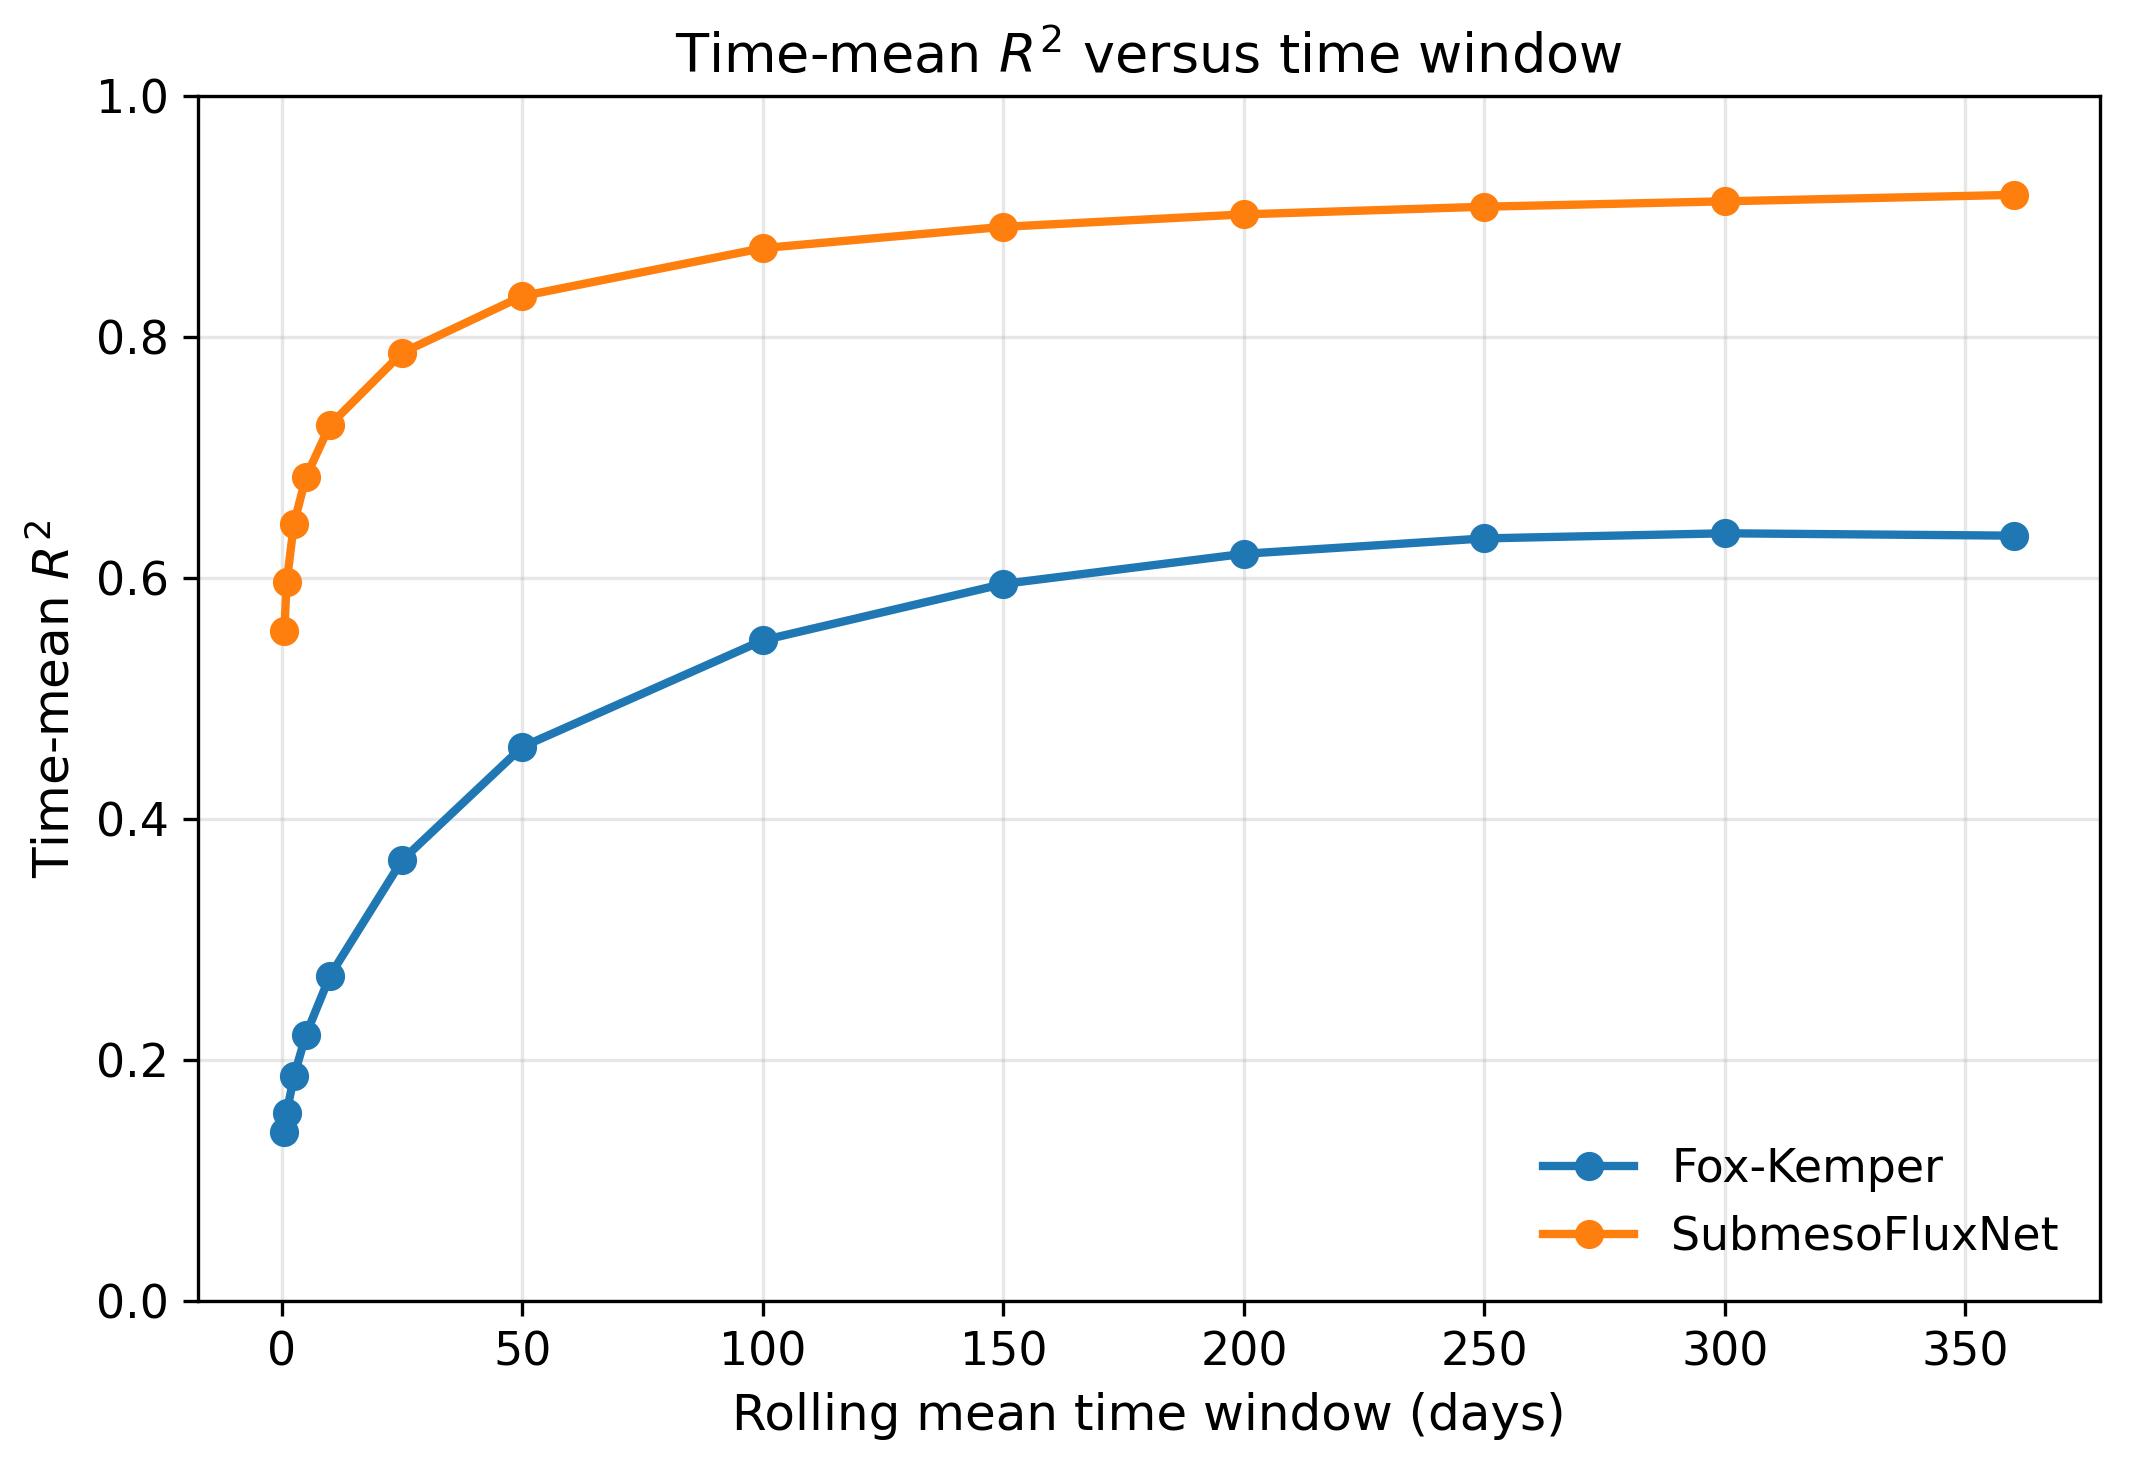

In [20]:
(fk_x, fk_r2), (ml_x, ml_r2) = plot_r2_window_comparison_from_data(
    y_true_a=wT_sel,
    y_pred_a=wT_sel_FK,
    y_true_b=y_true,
    y_pred_b=y_pred,
    windows=[1, 2, 5, 10, 20, 50, 100, 200, 300, 400, 500, 600, 720],
    label_a="Fox-Kemper",
    label_b="SubmesoFluxNet",
    savepath="climate_r2_comparison.png",
)